# BIOT 6900 · Module 5 Part 3 — Variant Interpretation & Pharmacogenomics (AD version)

This is the AD version of my Module 5 graded notebook. The original run used my assigned pharmacogene, **CYP2C19**, because the assignment restricted `MY_GENE` to five pharmacogenes, none of them Alzheimer's genes. This copy reruns the same pipeline on my Part I target and adds the AD-specific drug-gene interactions.

**What changed from the original run**
- **Q1 to Q6 run on HCN1**, the Part I lead target (Module 4 fpocket 0.878, ivabradine pocket confirmed against 8Y60). HCN1 has enough ClinVar P/LP and B/LB variants to calibrate CADD on its own, so the DPYD pooling used for CYP2C19 is not needed.
- **Frequency ceiling is 0.001**, defensible for a dominant epileptic-encephalopathy gene; Q3 checks that no P/LP variant is lost.
- **New Section 7: pharmacogenomics for AD drugs.**
  - **APOE ε4 and anti-amyloid antibodies** (lecanemab, donanemab): genotype sets ARIA risk, and the drug labels tie prescribing to APOE testing.
  - **CYP2C19 and citalopram/escitalopram**, used for depression and agitation in AD. This reuses the original CYP2C19 run (`data/CYP2C19.tsv`).
- Exported files are written as `images/module5_ad_*` so the original CYP2C19 outputs are untouched.

In [1]:
# Load secrets from a .env file (kept out of git) so no API key lives in this notebook.
import os, pathlib
for _d in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path.home() / "Documents/GitHub/biot6900"]:
    _f = _d / ".env"
    if _f.is_file():
        for _line in _f.read_text().splitlines():
            if "=" in _line and not _line.lstrip().startswith("#"):
                _k, _v = _line.split("=", 1)
                os.environ.setdefault(_k.strip(), _v.strip().strip("\"'"))
        break

In [2]:
import sys, time, re, json, pathlib
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)
GENES = ["CYP2C19", "CYP2C9", "VKORC1", "DPYD", "TPMT",
         "HCN1", "APOE"]          # AD VERSION — CHANGED: added HCN1 (Part I target) and APOE (top AD risk gene)
MV = "https://myvariant.info/v1"
AVI_FILE = DATA / "alphagenome_avi.tsv"

ANCHORS = {"rs1799853": "CYP2C9*2", "rs1057910": "CYP2C9*3",
           "rs9923231": "VKORC1 -1639G>A", "rs4244285": "CYP2C19*2",
           "rs12248560": "CYP2C19*17", "rs3918290": "DPYD*2A",
           "rs67376798": "DPYD c.2846A>T", "rs1142345": "TPMT*3C",
           # AD VERSION — NEW: APOE e4/e2 anchor alleles
           "rs429358": "APOE e4 (C130R)", "rs7412": "APOE e2 (R176C)"}

FIELDS = ",".join([
    "dbsnp.rsid",                        # the rs number
    "snpeff.ann.effect",                 # consequence term
    "cadd.phred",                        # CADD
    "dbnsfp.revel.score",                # REVEL
    "dbnsfp.alphamissense",              # AlphaMissense
    "dbnsfp.aa.ref", "dbnsfp.aa.alt", "dbnsfp.aa.pos", "dbnsfp.genename",
    "gnomad_genome.af.af", "gnomad_exome.af.af",
    "clinvar.rcv.clinical_significance",
    "clinvar.rcv.review_status",
    "clinvar.gene.symbol",
    "clinvar.variant_id",                # join key for CADD (see Section 3)
])

def first(x):
    """Some fields come back as a single value, some as a list. Take the first."""
    return (x[0] if x else None) if isinstance(x, list) else x

def dig(d, *path):
    """Walk a nested dict safely. Returns None if any level is missing."""
    for k in path:
        if not isinstance(d, dict):
            return None
        d = d.get(k)
        if d is None:
            return None
    return d

# ClinVar review status, as the familiar star rating
STARS = {"practice guideline": 4,
         "reviewed by expert panel": 3,
         "criteria provided, multiple submitters, no conflicts": 2,
         "criteria provided, conflicting classifications": 1,
         "criteria provided, conflicting interpretations": 1,
         "criteria provided, single submitter": 1,
         "no assertion criteria provided": 0,
         "no classification provided": 0}

# snpEff reports one effect per transcript. Keep the most severe one.
SEVERITY = ["stop_gained", "frameshift_variant", "splice_acceptor_variant",
            "splice_donor_variant", "start_lost", "stop_lost", "missense_variant",
            "splice_region_variant", "synonymous_variant", "5_prime_UTR_variant",
            "3_prime_UTR_variant", "intron_variant", "upstream_gene_variant",
            "downstream_gene_variant", "intergenic_region"]

def all_effects(h):
    """Every effect snpEff reported, across every transcript, split into single terms."""
    ann = dig(h, "snpeff", "ann")
    raw = [a.get("effect") for a in (ann if isinstance(ann, list) else [ann]) if isinstance(a, dict)]
    terms = []
    for e in raw:                       # snpEff emits compound terms joined by "&"
        if e:
            terms += [t for t in e.split("&") if t != "structural_interaction_variant"]
    return sorted(set(terms))

def worst_effect(h):
    """Collapse to ONE term: the most severe across all transcripts."""
    terms = all_effects(h)
    if not terms:
        return None
    return min(terms, key=lambda t: SEVERITY.index(t) if t in SEVERITY else 99)

def to_row(h, gene=None):
    aaref, aaalt = first(dig(h, "dbnsfp", "aa", "ref")), first(dig(h, "dbnsfp", "aa", "alt"))
    aapos = first(dig(h, "dbnsfp", "aa", "pos"))
    rcv = first(dig(h, "clinvar", "rcv")) or {}   # one record per submission; take the first
    rev = rcv.get("review_status")
    am = dig(h, "dbnsfp", "alphamissense", "score")
    return {
        "hgvs_g":        h.get("_id"),
        "rsid":          dig(h, "dbsnp", "rsid"),
        "gene":          first(dig(h, "clinvar", "gene", "symbol")) or first(dig(h, "dbnsfp", "genename")) or gene,
        "clinvar_id":    dig(h, "clinvar", "variant_id"),
        "consequence":   worst_effect(h),
        "consequence_all": ";".join(all_effects(h)),   # keep the full picture
        "aa_change":     f"{aaref}{aapos}{aaalt}" if (aaref and aaalt and aapos) else None,
        "cadd_phred":    dig(h, "cadd", "phred"),
        "revel":         first(dig(h, "dbnsfp", "revel", "score")),
        "alphamissense": first(am) if isinstance(am, list) else am,
        "gnomad_af":     dig(h, "gnomad_genome", "af", "af") or dig(h, "gnomad_exome", "af", "af"),
        "clinvar_sig":   rcv.get("clinical_significance"),
        "clinvar_stars": STARS.get(str(rev).lower(), 0),
    }

FORCE_REFETCH = False

# Known pharmacogenomic alleles, so we can check the fetch worked and
# recognise them later.
ANCHORS = {"rs1799853": "CYP2C9*2", "rs1057910": "CYP2C9*3",
           "rs9923231": "VKORC1 -1639G>A", "rs4244285": "CYP2C19*2",
           "rs12248560": "CYP2C19*17", "rs3918290": "DPYD*2A",
           "rs67376798": "DPYD c.2846A>T", "rs1142345": "TPMT*3C",
           # AD VERSION — NEW: APOE e4/e2 anchor alleles (second ANCHORS definition)
           "rs429358": "APOE e4 (C130R)", "rs7412": "APOE e2 (R176C)"}

def fetch_gene(gene, verbose=True):
    """Search ClinVar for one gene, annotate every hit, return a tidy DataFrame."""
    r = requests.get(f"{MV}/query", timeout=90, params={
        "q": f"clinvar.gene.symbol:{gene}", "assembly": "hg38",
        "fields": "_id", "size": 1000})
    r.raise_for_status()
    ids = [h["_id"] for h in r.json().get("hits", [])]
    if verbose:
        print(f"  {gene:9s} {len(ids):>5} variants found", end="", flush=True)

    rows = []
    for i in range(0, len(ids), 500):
        rr = requests.post(f"{MV}/variant", timeout=180,
                           data={"ids": ",".join(ids[i:i+500]),
                                 "fields": FIELDS, "assembly": "hg38"})
        rr.raise_for_status()
        rows += [to_row(h, gene) for h in rr.json()]
        time.sleep(0.3)                        # be polite to a free API

    df = pd.DataFrame(rows).drop_duplicates("hgvs_g")

    # MyVariant.info only carries genome-wide CADD on hg19. Ask the same
    # question on hg19 and join on the ClinVar variant ID, which is build-free.
    r19 = requests.get(f"{MV}/query", timeout=90, params={
        "q": f"clinvar.gene.symbol:{gene}", "assembly": "hg19",
        "fields": "clinvar.variant_id,cadd.phred", "size": 1000})
    r19.raise_for_status()
    hits19 = r19.json().get("hits", [])
    cadd = {}
    for h in hits19:
        vid = first(dig(h, "clinvar", "variant_id"))      # occasionally a list
        ph = dig(h, "cadd", "phred")
        if vid is not None and ph is not None:
            cadd[vid] = ph
    df["cadd_phred"] = df.clinvar_id.map(cadd)

    if len(ids) >= 1000 or len(hits19) >= 1000:
        print(f"\n  [!] {gene} hit the 1000-result cap. The two builds may have been")
        print( "      truncated to different sets, so some CADD scores will be missing.")
    if verbose:
        print(f"  ->  {len(df)} annotated")
    return df

def numeric(df):
    """Force the score columns to numbers. Strings here break everything later."""
    for c in ["cadd_phred", "revel", "alphamissense", "spliceai_dg",
              "spliceai_dl", "avi", "gnomad_af", "clinvar_stars"]:
        if c not in df.columns:
            df[c] = np.nan
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

def clinvar_label(sig):
    if not isinstance(sig, str): return "none"
    s = sig.lower()
    if "conflict" in s: return "conflicting"
    if "pathogenic" in s and "non-pathogenic" not in s: return "P/LP"
    if "benign" in s: return "B/LB"
    if "uncertain" in s: return "VUS"
    return "other"          # includes "drug response"

STRENGTH = [(18.7, "strong, pathogenic"), (4.3, "moderate, pathogenic"),
            (2.08, "supporting, pathogenic"), (0.48, "no evidence either way"),
            (0.23, "supporting, benign"), (0.053, "moderate, benign"),
            (0.0, "strong, benign")]

def strength_for(lr):
    if lr != lr: return "undefined"
    for cut, name in STRENGTH:
        if lr >= cut: return name
    return "strong, benign"

def calibrate(df, score_col, bands):
    d = df[df.label.isin(["P/LP", "B/LB"]) & df[score_col].notna()].copy()
    d["band"] = pd.cut(d[score_col], bands)
    n_p, n_b = (d.label == "P/LP").sum(), (d.label == "B/LB").sum()
    g = d.groupby("band", observed=False)
    out = pd.DataFrame({"n": g.size(),
                        "n_PLP": g.label.apply(lambda s: (s == "P/LP").sum()),
                        "n_BLB": g.label.apply(lambda s: (s == "B/LB").sum())})
    with np.errstate(divide="ignore", invalid="ignore"):
        out["LR+"] = ((out.n_PLP / max(n_p, 1)) / (out.n_BLB / max(n_b, 1))).round(2)
    out["evidence"] = out["LR+"].map(strength_for)
    out.attrs["n_p"], out.attrs["n_b"] = n_p, n_b
    return out

print("helpers loaded:", ", ".join(["fetch_gene", "numeric", "to_row", "clinvar_label",
                                    "calibrate", "strength_for", "worst_effect"]))

helpers loaded: fetch_gene, numeric, to_row, clinvar_label, calibrate, strength_for, worst_effect


In [3]:
MY_GENE = "HCN1"           # AD VERSION — CHANGED: was CYP2C19 (my assigned pharmacogene); HCN1 = Part I lead target
assert MY_GENE in GENES, f"MY_GENE must be one of {GENES}"
MY_FILE = DATA / f"{MY_GENE}.tsv"
print("working on", MY_GENE)

working on HCN1


In [4]:
# Q1
#   (a) if MY_FILE exists, read it; otherwise fetch_gene(MY_GENE) and save it
#   (b) pass it through numeric() so scores are numbers, not strings
#   (c) add a `label` column using clinvar_label()
#   (d) run and print the three quality checks described above
#
# Everything you need is already defined. This is about eight lines.

# Q1 (a): load from cache if present, otherwise fetch once and save
if MY_FILE.exists() and not FORCE_REFETCH:
    G = pd.read_csv(MY_FILE, sep="\t")
    print(f"loaded {len(G)} variants from cache: {MY_FILE}")
else:
    G = fetch_gene(MY_GENE)
    G.to_csv(MY_FILE, sep="\t", index=False)
    print(f"saved to {MY_FILE}")

# (b) scores as numbers, (c) ClinVar label
G = numeric(G)
G["label"] = G.clinvar_sig.map(clinvar_label)

# (d) the three quality checks
print("\n--- CHECK 1: count ---")
print(f"{len(G)} variants for {MY_GENE}")
print(G.label.value_counts().to_string())

print("\n--- CHECK 2: anchors ---")
# AD VERSION — CHANGED: HCN1 has no star-allele anchors, so the P/LP count is the sanity check instead.
# AD VERSION — 'if True:' keeps the original loop body's indentation unchanged.
own = {rs: n for rs, n in ANCHORS.items() if n.startswith(MY_GENE)}
if not own:
    print(f"no anchor alleles for {MY_GENE} (not a pharmacogene, so no star alleles);")
    print(f"sanity check instead: {(G.label == 'P/LP').sum()} P/LP variants returned")
for rs, name in own.items():
    if True:
        hit = G[G.rsid.astype(str).str.contains(rs, na=False)]
        print(f"{name} ({rs}): {'FOUND' if len(hit) else 'MISSING'}")
        if len(hit):
            print(hit[["rsid", "consequence", "clinvar_sig", "gnomad_af"]].to_string(index=False))

print("\n--- CHECK 3: score columns populated ---")
cov = G[["cadd_phred", "revel", "alphamissense", "gnomad_af"]].notna().mean().mul(100).round(1)
print(cov.to_string())

os.makedirs("images", exist_ok=True)
# AD VERSION — CHANGED: output file renamed images/module5_part3_* -> images/module5_ad_* so the original CYP2C19 outputs are kept.
G.label.value_counts().rename_axis("label").reset_index(name="n").to_csv("images/module5_ad_clinvar_label_counts.csv", index=False)
cov.rename("pct_populated").rename_axis("score_column").reset_index().to_csv("images/module5_ad_score_column_coverage.csv", index=False)

loaded 1000 variants from cache: data/HCN1.tsv

--- CHECK 1: count ---
1000 variants for HCN1
label
VUS            513
B/LB           441
P/LP            43
conflicting      3

--- CHECK 2: anchors ---
no anchor alleles for HCN1 (not a pharmacogene, so no star alleles);
sanity check instead: 43 P/LP variants returned

--- CHECK 3: score columns populated ---
cadd_phred       86.1
revel            53.3
alphamissense    53.6
gnomad_af        40.0


In [5]:
# Q2
#   (a) group G by consequence and count non-null scores per tool
#   (b) print the table, plus the overall percentage scored by each tool
#   (c) print which consequence classes have ZERO REVEL scores
#
# Hint: .groupby("consequence") then .apply(lambda s: s.notna().sum())

TOOLS = ["cadd_phred", "revel", "alphamissense"]

# (a) per consequence class: total variants and non-null scores per tool
cov = G.groupby("consequence").apply(
    lambda d: pd.Series({"n": len(d), **{t: d[t].notna().sum() for t in TOOLS}}),
    include_groups=False).sort_values("n", ascending=False).astype(int)

# (b) the table, plus overall percentage scored by each tool
print("Variants scored per tool, by consequence class:\n")
print(cov.to_string())
print("\nOverall % of variants scored:")
print((G[TOOLS].notna().mean() * 100).round(1).to_string())

# (c) consequence classes where REVEL scored nothing
no_revel = cov.index[cov.revel == 0].tolist()
print("\nClasses with ZERO REVEL scores:", no_revel)

os.makedirs("images", exist_ok=True)
# AD VERSION — CHANGED: output file renamed images/module5_part3_* -> images/module5_ad_* so the original CYP2C19 outputs are kept.
cov.rename_axis("consequence").reset_index().to_csv("images/module5_ad_scored_by_consequence.csv", index=False)
(G[TOOLS].notna().mean() * 100).round(1).rename_axis("tool").reset_index(name="pct_scored").to_csv("images/module5_ad_overall_pct_scored.csv", index=False)

Variants scored per tool, by consequence class:

                                  n  cadd_phred  revel  alphamissense
consequence                                                          
missense_variant                536         532    533            533
synonymous_variant              279         277      0              0
intron_variant                   75          29      0              2
splice_region_variant            32           6      0              1
stop_gained                      16          15      0              0
frameshift_variant               13           0      0              0
disruptive_inframe_deletion       7           0      0              0
splice_donor_variant              4           0      0              0
upstream_gene_variant             2           2      0              0
3_prime_UTR_variant               1           0      0              0
conservative_inframe_insertion    1           0      0              0
disruptive_inframe_insertion      1      

In [6]:
# Q3
#   (a) set MAX_AF to a threshold you can defend for YOUR gene
#   (b) report how many variants it removes
#   (c) CRITICAL: list the P/LP or "drug response" variants your filter removes.
#       If it removes a known functional allele, either change the threshold or
#       justify keeping it in your report.
#   (d) for contrast, report what a 0.001 rare-disease filter would have removed
#   (e) set G to the filtered set

# (a) Threshold
# AD VERSION — CHANGED: MAX_AF 0.5 -> 0.001. HCN1 is an autosomal-dominant developmental and epileptic encephalopathy gene: every ClinVar
# P/LP variant is ultra-rare (max gnomAD AF ~4e-5). A standard rare-disease ceiling is defensible
# here, unlike for CYP2C19 where functional alleles are common. The AD GWAS signal near HCN1 is a
# common non-coding SNP and is NOT what this ClinVar-based interpretation is scoring.
MAX_AF = 0.001

# Variants with no gnomAD frequency are KEPT: missing is not the same as common.
def too_common(d, cutoff):
    return d[d.gnomad_af > cutoff]

# (b) what the chosen threshold removes
removed = too_common(G, MAX_AF)
print(f"MAX_AF = {MAX_AF}: removes {len(removed)} of {len(G)} variants "
      f"({G.gnomad_af.isna().sum()} have no AF and are kept)")
cols = ["rsid", "consequence", "clinvar_sig", "label", "gnomad_af"]
print(removed[cols].to_string(index=False))

# (c) CRITICAL: any P/LP or drug-response variants lost?
def functional(d):
    return d[(d.label == "P/LP") | d.clinvar_sig.astype(str).str.contains("drug response", case=False)]

lost = functional(removed)
print(f"\nP/LP or drug-response variants removed by MAX_AF={MAX_AF}: {len(lost)}")
if len(lost): print(lost[cols].to_string(index=False))

# (d) contrast with a rare-disease filter
rare = too_common(G, 0.001)
lost_rare = functional(rare)
print(f"\nRare-disease filter (0.001) would remove {len(rare)} variants, "
      f"including {len(lost_rare)} P/LP or drug-response:")
print(lost_rare[cols].sort_values("gnomad_af").to_string(index=False))
print("  anchors lost:", [a for a in ANCHORS if a in set(lost_rare.rsid.astype(str))])

# (e) apply
G = G[~(G.gnomad_af > MAX_AF)].copy()
print(f"\nG after filtering: {len(G)} variants")

os.makedirs("images", exist_ok=True)
# AD VERSION — CHANGED: output file renamed images/module5_part3_* -> images/module5_ad_* so the original CYP2C19 outputs are kept.
removed[cols].to_csv("images/module5_ad_af_filter_removed_variants.csv", index=False)
lost[cols].to_csv("images/module5_ad_af_filter_lost_functional_variants.csv", index=False)
lost_rare[cols].to_csv("images/module5_ad_rare_disease_filter_lost_functional_variants.csv", index=False)

MAX_AF = 0.001: removes 26 of 1000 variants (600 have no AF and are kept)
        rsid           consequence          clinvar_sig label  gnomad_af
   rs4866929        intron_variant               Benign  B/LB   0.342157
 rs544994462      missense_variant Benign/Likely benign  B/LB   0.003491
 rs188586020 splice_region_variant Benign/Likely benign  B/LB   0.001771
 rs866912042        intron_variant        Likely benign  B/LB   0.022174
  rs16902099        intron_variant               Benign  B/LB   0.016284
  rs75449215        intron_variant               Benign  B/LB   0.033493
  rs56217199    synonymous_variant               Benign  B/LB   0.001841
 rs374836434        intron_variant        Likely benign  B/LB   0.005436
 rs113202045        intron_variant               Benign  B/LB   0.022919
  rs75228534        intron_variant               Benign  B/LB   0.031253
  rs78789554 upstream_gene_variant        Likely benign  B/LB   0.004479
         NaN        intron_variant        Likely b

            n  n_PLP  n_BLB    LR+              evidence
band                                                    
(0, 10]   217      0    217   0.00        strong, benign
(10, 20]  106      2    104   0.17      moderate, benign
(20, 25]   32     11     21   4.50  moderate, pathogenic
(25, 30]   27     20      7  24.53    strong, pathogenic
(30, 50]   11      8      3  22.89    strong, pathogenic

Calibration rests on 41 P/LP and 352 B/LB variants (393 total), all from HCN1.

Bands resting on fewer than 10 variants: 0 of 5

REVEL calibration, for comparison (missense only):
             n  n_PLP  n_BLB   LR+                evidence
band                                                      
(0.0, 0.2]  11      0     11  0.00          strong, benign
(0.2, 0.4]  38      0     38  0.00          strong, benign
(0.4, 0.6]  11      3      8  0.59  no evidence either way
(0.6, 0.8]  19     15      4  5.95    moderate, pathogenic
(0.8, 1.0]  27     23      4  9.12    moderate, pathogenic


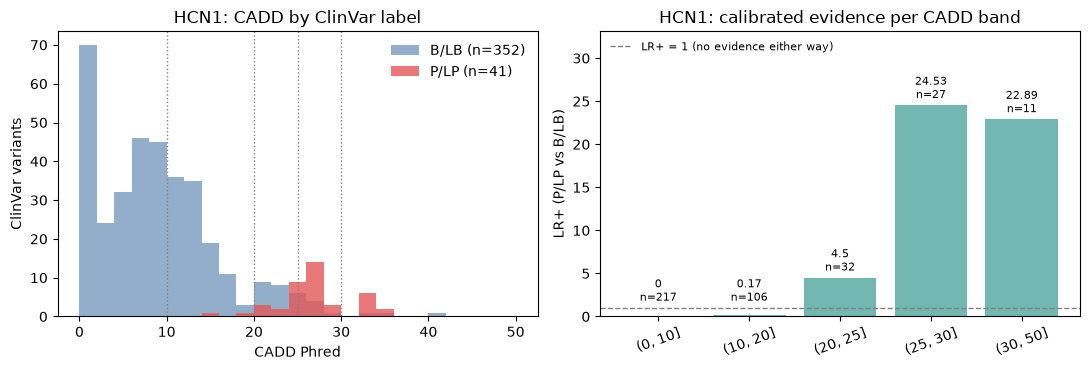

In [7]:
# Q4: calibrate CADD on HCN1 itself.
# AD VERSION — REMOVED: the DPYD pooling block (fetch DPYD, filter, pd.concat) that CYP2C19 needed because it had 0 P/LP.
# Unlike CYP2C19 (0 P/LP, had to pool with DPYD), HCN1 has enough labelled variants
# to calibrate on its own, so no pooling is needed.
P = G

# AD VERSION — CHANGED: reason for CADD rewritten for HCN1 (was 'best coverage in CYP2C19').
# CADD covers non-missense classes too (Q2); REVEL is run alongside for comparison only.
SCORE_COL = "cadd_phred"
BANDS     = [0, 10, 20, 25, 30, 50]

cal = calibrate(P, SCORE_COL, BANDS)
print(cal.to_string())

# (b) how many labelled variants does this rest on?
print(f"\nCalibration rests on {cal.attrs['n_p']} P/LP and {cal.attrs['n_b']} B/LB variants "
      f"({cal.attrs['n_p'] + cal.attrs['n_b']} total), all from {MY_GENE}.")

# (c) thin bands
thin = cal[cal.n < 10]
print(f"\nBands resting on fewer than 10 variants: {len(thin)} of {len(cal)}")
if len(thin): print(thin[["n", "n_PLP", "n_BLB", "LR+"]].to_string())

# AD VERSION — NEW: REVEL calibration for comparison.
# comparison: REVEL (missense only)
cal_revel = calibrate(P, "revel", [0, .2, .4, .6, .8, 1.0])
print(f"\nREVEL calibration, for comparison (missense only):\n{cal_revel.to_string()}")

# AD VERSION — NEW: calibration figure, saved to images/module5_ad_hcn1_cadd_calibration.png.
# Figure: CADD by ClinVar label with the calibration bands
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
lab = P[P.label.isin(["P/LP", "B/LB"]) & P[SCORE_COL].notna()]
bins = np.arange(0, 51, 2)
a1.hist(lab[lab.label == "B/LB"][SCORE_COL], bins=bins, alpha=.6, label=f"B/LB (n={(lab.label=='B/LB').sum()})", color="#4C78A8")
a1.hist(lab[lab.label == "P/LP"][SCORE_COL], bins=bins, alpha=.8, label=f"P/LP (n={(lab.label=='P/LP').sum()})", color="#E45756")
for b in BANDS[1:-1]: a1.axvline(b, color="grey", ls=":", lw=1)
a1.set_xlabel("CADD Phred"); a1.set_ylabel("ClinVar variants"); a1.legend(frameon=False)
a1.set_title(f"{MY_GENE}: CADD by ClinVar label")
lr = cal["LR+"].replace([np.inf], np.nan)
a2.bar(range(len(cal)), lr.fillna(0), color="#72B7B2")
# AD VERSION — CHANGED: labels for bars below the LR+ = 1 line sit above that line so they don't overlap it.
for i, (v, n) in enumerate(zip(cal["LR+"], cal["n"])):
    h = 0 if not np.isfinite(v) else v
    a2.text(i, max(h, 1) + .4, ("inf" if v == np.inf else f"{v:g}") + f"\nn={n}", ha="center", va="bottom", fontsize=8)
a2.set_xticks(range(len(cal))); a2.set_xticklabels([str(b) for b in cal.index], rotation=20)
# AD VERSION — CHANGED: the LR+ = 1 reference line is dashed and labelled so it doesn't read as a second x-axis.
a2.axhline(1, color="grey", lw=1, ls="--", label="LR+ = 1 (no evidence either way)")
a2.legend(loc="upper left", frameon=False, fontsize=8)
a2.set_ylabel("LR+ (P/LP vs B/LB)")
# AD VERSION — NEW: headroom above the tallest finite bar so the "LR+ / n=" labels are not cut off.
a2.set_ylim(0, np.nanmax(lr.values) * 1.35)
a2.set_title(f"{MY_GENE}: calibrated evidence per CADD band")
fig.tight_layout()
os.makedirs("images", exist_ok=True)
fig.savefig("images/module5_ad_hcn1_cadd_calibration.png", dpi=200, bbox_inches="tight"); plt.show()

# AD VERSION — CHANGED: output file renamed images/module5_part3_* -> images/module5_ad_* so the original CYP2C19 outputs are kept.
# AD VERSION — NEW: REVEL calibration bands also saved.
_cal = cal.copy(); _cal.index = _cal.index.astype(str)
_cal.rename_axis("band").to_csv("images/module5_ad_cadd_calibration_bands.csv")
_cr = cal_revel.copy(); _cr.index = _cr.index.astype(str)
_cr.rename_axis("band").to_csv("images/module5_ad_revel_calibration_bands.csv")

In [8]:
# Q5
#   (a) take the VUS rows from G
#   (b) map each one to the evidence strength of its calibrated band
#   (c) count how many move towards pathogenic, towards benign, and stay put
#   (d) export to pgx_classified_<MY_GENE>.csv with these columns:
#       rsid, gene, consequence, aa_change, your score column, gnomad_af,
#       evidence, provisional_call

# AD VERSION — CHANGED: was the VUS rows of CYP2C19; now HCN1
# (a) the VUS rows of HCN1
vus = G[G.label == "VUS"].copy()

# (b) map each score to its band, then to that band's calibrated evidence strength.
# Bands come from the pooled calibration `cal` in Q4. A VUS with no CADD score, or one
# outside the bands, gets no evidence.
vus["band"] = pd.cut(vus[SCORE_COL], BANDS)
vus["evidence"] = vus.band.map(cal.evidence.to_dict()).astype(object)
vus["evidence"] = vus.evidence.where(vus.evidence.notna(), "not scored")

def provisional(ev):
    if "pathogenic" in ev: return "VUS, leaning pathogenic"
    if "benign" in ev:     return "VUS, leaning benign"
    return "VUS"          # includes "no evidence either way" and "not scored"

vus["provisional_call"] = vus.evidence.map(provisional)

# (c) how many move?
print(f"{len(vus)} VUS in {MY_GENE}\n")
print(vus.evidence.value_counts().to_string())
print()
print(vus.provisional_call.value_counts().to_string())

# (d) export
OUT = f"variant_classified_{MY_GENE}.csv"   # AD VERSION — CHANGED: was pgx_classified_<gene>.csv; HCN1 is not a pharmacogene
out_cols = ["rsid", "gene", "consequence", "aa_change", SCORE_COL, "gnomad_af",
            "evidence", "provisional_call"]
vus[out_cols].to_csv(OUT, index=False)
print(f"\nwrote {OUT} ({len(vus)} rows)")

os.makedirs("images", exist_ok=True)
# AD VERSION — CHANGED: output file renamed images/module5_part3_* -> images/module5_ad_* so the original CYP2C19 outputs are kept.
vus.evidence.value_counts().rename_axis("evidence").reset_index(name="n").to_csv("images/module5_ad_vus_evidence_counts.csv", index=False)
vus.provisional_call.value_counts().rename_axis("provisional_call").reset_index(name="n").to_csv("images/module5_ad_vus_provisional_calls.csv", index=False)
vus[out_cols].to_csv("images/module5_ad_vus_classified.csv", index=False)

513 VUS in HCN1

evidence
strong, pathogenic      170
moderate, pathogenic    131
moderate, benign         98
not scored               66
strong, benign           48

provisional_call
VUS, leaning pathogenic    301
VUS, leaning benign        146
VUS                         66



wrote variant_classified_HCN1.csv (513 rows)


In [9]:
SKIP_ATLAS   = False
MAX_VARIANTS = 200

import os
ATLAS_STATUS = "not run"

def to_variant_string(hgvs):
    """Atlas wants 1-based GRCh38 chr:pos:ref>alt. It does NOT accept rsIDs."""
    m = re.match(r"(chr[\w]+):g\.(\d+)([ACGT])>([ACGT])", str(hgvs))
    return f"{m.group(1)}:{m.group(2)}:{m.group(3)}>{m.group(4)}" if m else None

# AD VERSION — NEW: reuse a cached Atlas run instead of re-querying on every Run All.
AVI_CACHE = DATA / f"avi_{MY_GENE}.tsv"
if AVI_CACHE.exists():
    avi = pd.read_csv(AVI_CACHE, sep="\t")
    G = G.merge(avi.drop(columns="rsid"), on="hgvs_g", how="left"); G["avi"] = G.avi_phred
    ATLAS_STATUS = "cached"
    print(f"loaded cached Atlas scores: {AVI_CACHE} ({len(avi)} variants)")
elif SKIP_ATLAS:
    print("SKIPPED. Disclose this in your report and answer Q6.2 from reasoning.")
    ATLAS_STATUS = "skipped"
else:
    try:
        from alphagenome.atlas import atlas
        from alphagenome.data import genome
        key = os.environ.get("ALPHAGENOME_API_KEY") or os.environ.get("ALPHA_GENOME_API_KEY")
        if not key:
            raise RuntimeError(
                "No API key in your environment. Did you relaunch Jupyter from a NEW\n"
                "  terminal after setting it? Check with:\n"
                "    import os; print(os.environ.get('ALPHAGENOME_API_KEY'))\n"
                "  Or set SKIP_ATLAS = True.")
        client = atlas.create(key, timeout=30)

        pri = G.assign(_nc=~G.consequence.fillna("").str.contains("missense")) \
               .sort_values("_nc", ascending=False).head(MAX_VARIANTS)
        rows, errs = [], 0
        for n, (_, r) in enumerate(pri.iterrows(), 1):
            vs = to_variant_string(r.hgvs_g)
            if not vs:
                continue
            try:
                res = client.query_variant(
                    genome.Variant.from_str(vs),
                    requested_scorers=["AVI_SCORE", "AVI_SCORE_FEATURE_IMPORTANCE"])
                ad = res["AVI_SCORE"]
                cdf = float(ad.layers["quantiles"][0, 0])
                fi = res["AVI_SCORE_FEATURE_IMPORTANCE"]
                # AD VERSION — CHANGED: also store hgvs_g, so the merge below has a unique key.
                rows.append({"hgvs_g": r.hgvs_g, "rsid": r.rsid,
                             "avi_phred": round(-10*np.log10(max(1-cdf, 1e-12)), 2),
                             "top_feature": fi.var["name"].values[int(np.argmax(np.abs(fi.X[0])))]})
            except Exception:
                errs += 1
            if n % 50 == 0:
                print(f"  {n}/{len(pri)} queried", flush=True)

        avi = pd.DataFrame(rows)
        if len(avi):
            avi.to_csv(DATA / f"avi_{MY_GENE}.tsv", sep="\t", index=False)
            # AD VERSION — CHANGED: merge on hgvs_g instead of rsid (the original cross-joined rows): many HCN1 variants have no rsID, and merging on a
            # NaN rsid would cross-join every unnamed variant with every other one
            G = G.merge(avi.drop(columns="rsid"), on="hgvs_g", how="left")
            G["avi"] = G.avi_phred
            ATLAS_STATUS = "queried live"
            print(f"\nscored {len(avi)} variants ({errs} failures)")
    except ImportError:
        print('alphagenome not installed. pip install "alphagenome>=0.9.0", then restart.')
        print("Or set SKIP_ATLAS = True.")
    except Exception as e:
        print(f"{type(e).__name__}: {e}")

if "avi" not in G.columns: G["avi"] = np.nan
if "top_feature" not in G.columns: G["top_feature"] = np.nan
G["avi"] = pd.to_numeric(G["avi"], errors="coerce")

if G.avi.notna().sum() > 0:
    a = G[G.avi.notna()]
    cols = [c for c in ["rsid", "consequence", "avi_phred", "top_feature",
                        "revel", "cadd_phred", "label"] if c in a.columns]
    # AD VERSION — NEW: confirm the merge did not duplicate rows.
    print(f"\nG still has {len(G)} rows after the merge")
    print(f"\nhighest-impact {MY_GENE} variants by AVI\n")
    print(a.sort_values("avi", ascending=False)[cols].head(10).to_string(index=False))
    print("\nwhat is driving the scores (read this BEFORE the numbers)")
    print(a.top_feature.value_counts().head(8).to_string())
else:
    nc = G[~G.consequence.fillna("").str.contains("missense")]
    print(f"\nnon-missense variants in {MY_GENE}, which is what the Atlas is for: {len(nc)}")
    print(nc.consequence.value_counts().to_string())

print(f"\n[Atlas status: {ATLAS_STATUS}]")

os.makedirs("images", exist_ok=True)
if G.avi.notna().sum() > 0:
    # AD VERSION — CHANGED: output file renamed images/module5_part3_* -> images/module5_ad_* so the original CYP2C19 outputs are kept.
    a.sort_values("avi", ascending=False)[cols].head(10).to_csv("images/module5_ad_atlas_top_variants.csv", index=False)
    a.top_feature.value_counts().rename_axis("top_feature").reset_index(name="n").to_csv("images/module5_ad_atlas_top_features.csv", index=False)
else:
    nc.consequence.value_counts().rename_axis("consequence").reset_index(name="n").to_csv("images/module5_ad_non_missense_consequences.csv", index=False)

loaded cached Atlas scores: data/avi_HCN1.tsv (175 variants)

G still has 974 rows after the merge

highest-impact HCN1 variants by AVI

        rsid          consequence  avi_phred         top_feature  revel  cadd_phred label
         NaN          stop_gained      38.98 PROTEIN_TERMINATION    NaN        43.0   VUS
rs2111983087          stop_gained      38.80 PROTEIN_TERMINATION    NaN        42.0   VUS
 rs541911994          stop_gained      38.46 PROTEIN_TERMINATION    NaN        39.0   VUS
         NaN          stop_gained      37.57 PROTEIN_TERMINATION    NaN        35.0   VUS
 rs539896753          stop_gained      35.96 PROTEIN_TERMINATION    NaN        41.0   VUS
rs2111846846          stop_gained      35.00 PROTEIN_TERMINATION    NaN        43.0   VUS
rs1745526984          stop_gained      33.74 PROTEIN_TERMINATION    NaN        38.0   VUS
         NaN          stop_gained      33.60 PROTEIN_TERMINATION    NaN        37.0   VUS
rs1744762137          stop_gained      32.56 PROTEIN_

In [10]:
d = G.copy()
coding = d.consequence.isin(["missense_variant", "synonymous_variant"])

d["flag_cadd_vs_revel"]  = (d.cadd_phred > 25) & (d.revel < 0.35)
d["flag_revel_vs_am"]    = (d.revel - d.alphamissense).abs() > 0.4
d["flag_scored_but_vus"] = (d.label == "VUS") & (d.revel > 0.7)
d["flag_common_but_plp"] = (d.gnomad_af > 0.01) & (d.label.isin(["P/LP", "other"]))
d["flag_no_tool_at_all"] = d[["revel", "alphamissense", "cadd_phred"]].isna().all(axis=1)
if d.avi.notna().any():
    d["flag_atlas_only"] = (d.avi > 20) & d.revel.isna() & d.alphamissense.isna()

flags = [c for c in d.columns if c.startswith("flag_")]
print(f"discordant variants in {MY_GENE}\n")
print(d[flags].sum().to_string())

hits = d[d[flags].any(axis=1)]
cols = [c for c in ["rsid", "note", "consequence", "consequence_all", "aa_change",
                    "cadd_phred", "revel", "alphamissense", "avi", "gnomad_af",
                    "label"] if c in d.columns]
print(f"\n{len(hits)} variants trip at least one rule\n")
print(hits[cols].head(15).to_string(index=False) if len(hits) else "  (none)")

if len(hits) == 0:
    print("\nNone. That is a legitimate result. Say so in your report and explain why")
    print("this gene's variants are concordant, rather than loosening the rules until")
    print("something fires.")

os.makedirs("images", exist_ok=True)
# AD VERSION — CHANGED: output file renamed images/module5_part3_* -> images/module5_ad_* so the original CYP2C19 outputs are kept.
d[flags].sum().rename_axis("flag").reset_index(name="n_variants").to_csv("images/module5_ad_discordance_flag_counts.csv", index=False)
hits[cols].to_csv("images/module5_ad_discordant_variants.csv", index=False)

discordant variants in HCN1

flag_cadd_vs_revel       5
flag_revel_vs_am        42
flag_scored_but_vus    126
flag_common_but_plp      0
flag_no_tool_at_all    128
flag_atlas_only         18

312 variants trip at least one rule

        rsid           consequence                      consequence_all aa_change  cadd_phred  revel  alphamissense   avi  gnomad_af label
rs1744762137           stop_gained                          stop_gained     Q754X        35.0    NaN            NaN 32.56        NaN   VUS
rs1579867065      missense_variant                     missense_variant     G382A        24.3  0.729         0.9977   NaN        NaN   VUS
         NaN splice_region_variant intron_variant;splice_region_variant       NaN         NaN    NaN            NaN   NaN        NaN   VUS
rs2111904917      missense_variant                     missense_variant     M512I        33.0  0.912         0.9996   NaN        NaN   VUS
         NaN      missense_variant                     missense_variant     

---
## 7 · Pharmacogenomics for Alzheimer's disease drugs

HCN1 has no pharmacogenomic guideline: no AD drug is dosed or chosen by HCN1 genotype. So the drug-gene recommendations for AD patients have to come from the two genes that *do* change AD prescribing today:

1. **APOE** decides the brain-swelling risk (ARIA) on the approved anti-amyloid antibodies, lecanemab and donanemab (7.1 and 7.2).
2. **CYP2C19** decides how much citalopram/escitalopram reaches the blood. These antidepressants are commonly used for depression and agitation in AD (7.3).

### 7.1 · What the variant tools say about the APOE alleles

**Background.** Everyone carries two copies of APOE, and each copy is one of three common versions: ε2, ε3 or ε4. Which version a copy is depends on two DNA positions, rs429358 and rs7412 (key printed under the table). ε4 is the strongest common genetic risk factor for late-onset AD: one copy raises risk roughly 3-fold, two copies roughly 8- to 12-fold. ε2 is protective.

**What this cell does.** It looks up those two positions in the same ClinVar/CADD/REVEL/AlphaMissense table used for HCN1, and asks what the tools from Q1–Q6 would have said about them.

**How to read the output.**
- `revel` and `alphamissense` are low for ε4 (0.23 and 0.04 on a 0–1 scale), so the tools call the biggest AD risk allele *benign*. They were trained to spot variants that break a protein and cause rare inherited disease. ε4 is a common variant that changes how the protein behaves, which is a different question.
- `clinvar_sig` for ε2 says *Pathogenic*. That label is for a cholesterol disorder (type III hyperlipoproteinemia), not AD, where ε2 protects. A ClinVar label only applies to the disease it was filed for.
- `removed_by_0.001_filter` is True for both, because both alleles are common (15.7% and 7.8% of chromosomes). The rare-variant filter from Q3 would have deleted them before any tool saw them.

**Takeaway:** pathogenicity tools are the wrong instrument for APOE. In the clinic, APOE is handled by directly genotyping a patient's two copies (e.g. ε3/ε4), which is what 7.2 uses.

In [11]:
# AD VERSION — NEW (Section 7.1): APOE e4/e2 tool scores, and whether a rare-variant filter would drop them.
A = DATA / "APOE.tsv"
if A.exists() and not FORCE_REFETCH:
    A = pd.read_csv(A, sep="\t")
else:
    _a = fetch_gene("APOE"); _a.to_csv(A, sep="\t", index=False); A = _a
A = numeric(A); A["label"] = A.clinvar_sig.map(clinvar_label)

apoe_cols = ["rsid", "aa_change", "consequence", "cadd_phred", "revel", "alphamissense",
             "gnomad_af", "clinvar_sig", "clinvar_stars"]
apoe = A[A.rsid.isin(["rs429358", "rs7412"])][apoe_cols].copy()
apoe.insert(1, "allele", apoe.rsid.map(ANCHORS))
apoe["band_evidence (HCN1 CADD cal.)"] = pd.cut(apoe.cadd_phred, BANDS).map(cal.evidence.to_dict())
apoe["removed_by_0.001_filter"] = apoe.gnomad_af > 0.001
print(apoe.to_string(index=False))

print("""
APOE haplotypes are defined by these two SNPs together:
  e2 = rs429358 T + rs7412 T     e3 = rs429358 T + rs7412 C     e4 = rs429358 C + rs7412 C
""")
apoe.to_csv("images/module5_ad_apoe_allele_scores.csv", index=False)

    rsid          allele aa_change      consequence  cadd_phred  revel  alphamissense  gnomad_af clinvar_sig  clinvar_stars band_evidence (HCN1 CADD cal.)  removed_by_0.001_filter
  rs7412 APOE e2 (R176C)     R176C missense_variant       12.34  0.588         0.4222   0.077880  Pathogenic              0               moderate, benign                     True
rs429358 APOE e4 (C130R)     C130R missense_variant       24.80  0.229         0.0365   0.157101 association              0           moderate, pathogenic                     True

APOE haplotypes are defined by these two SNPs together:
  e2 = rs429358 T + rs7412 T     e3 = rs429358 T + rs7412 C     e4 = rs429358 C + rs7412 C



### 7.2 · APOE genotype → anti-amyloid antibody recommendation

**Background.** Lecanemab (Leqembi) and donanemab (Kisunla) are antibodies that clear amyloid plaques and modestly slow early AD. Their main risk is **ARIA**, short for amyloid-related imaging abnormalities: brain swelling (ARIA-E) or small bleeds (ARIA-H) seen on MRI. Most cases cause no symptoms, but some are serious. ARIA risk rises with the number of APOE ε4 copies, so both US labels carry a boxed warning and say to test APOE before starting treatment.

**What this cell does.** It turns the label numbers into a genotype → recommendation table and a figure.

**How to read the table** (one row per number of ε4 copies; numbers are quoted from Section 5.1 of each US label, Leqembi revised 7/2026, Kisunla revised 7/2025):
- `lecanemab ARIA %` vs `lecanemab placebo ARIA %`: the share of trial patients with any ARIA on the drug vs on placebo. For two ε4 copies it is 45% on lecanemab vs 22% on placebo. The gap between them is the part the drug adds.
- `symptomatic ARIA-E %`: the share whose swelling caused symptoms. This rises most steeply with ε4 dose for lecanemab (1% → 2% → 9%).
- `recommendation`: what a prescriber does with each genotype. Non-carriers and one-copy carriers are eligible with standard MRI monitoring. Two-copy carriers have the highest risk and need a shared decision. The EU approved lecanemab only for patients with zero or one ε4 copy.

**Takeaway:** this is the most actionable genetic result in the case study. A patient's APOE genotype directly changes whether, and how carefully, they receive an approved AD drug.

  APOE e4 copies   example genotypes  lecanemab ARIA %  lecanemab placebo ARIA %  lecanemab symptomatic ARIA-E %  donanemab ARIA %  donanemab placebo ARIA %  donanemab symptomatic ARIA-E %                                                                                                                                                            recommendation                       actionability
 0 (non-carrier) e3/e3, e2/e3, e2/e2                13                         4                               1                25                        12                               4                                                                                                             Eligible; test before starting, standard ARIA MRI monitoring. Label-directed test (boxed warning)
1 (heterozygote)        e3/e4, e2/e4                19                         9                               2                36                        13                               7                      

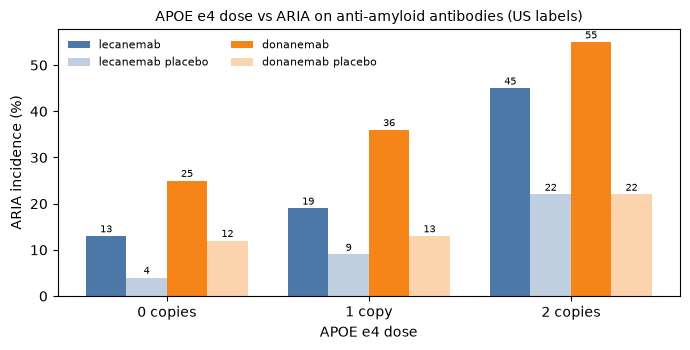

In [12]:
# AD VERSION — NEW (Section 7.2): APOE genotype -> ARIA risk on lecanemab/donanemab (US label numbers),
# AD VERSION — with recommendation table and figure.
aria = pd.DataFrame({
    "APOE e4 copies": ["0 (non-carrier)", "1 (heterozygote)", "2 (homozygote)"],
    "example genotypes": ["e3/e3, e2/e3, e2/e2", "e3/e4, e2/e4", "e4/e4"],
    # US prescribing information, Section 5.1 "ApoE e4 Carrier Status" (any ARIA, drug vs placebo)
    "lecanemab ARIA %": [13, 19, 45],      "lecanemab placebo ARIA %": [4, 9, 22],
    "lecanemab symptomatic ARIA-E %": [1, 2, 9],
    "donanemab ARIA %": [25, 36, 55],      "donanemab placebo ARIA %": [12, 13, 22],
    "donanemab symptomatic ARIA-E %": [4, 7, 8],
    "recommendation": [
        "Eligible; test before starting, standard ARIA MRI monitoring.",
        "Eligible; discuss intermediate ARIA risk; standard ARIA MRI monitoring.",
        "Highest ARIA risk incl. symptomatic/serious ARIA; shared decision-making; "
        "EU lecanemab authorisation excludes e4 homozygotes; if treated in the US, close MRI monitoring.",
    ],
    "actionability": ["Label-directed test (boxed warning)"] * 3,
})
print(aria.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(3); w = .2
bars = [("lecanemab ARIA %", "lecanemab", "#4C78A8", 1.0), ("lecanemab placebo ARIA %", "lecanemab placebo", "#4C78A8", .35),
        ("donanemab ARIA %", "donanemab", "#F58518", 1.0), ("donanemab placebo ARIA %", "donanemab placebo", "#F58518", .35)]
for k, (col, lab, colr, al) in enumerate(bars):
    xs = x + (k - 1.5) * w
    ax.bar(xs, aria[col], w, label=lab, color=colr, alpha=al)
    for xi, v in zip(xs, aria[col]): ax.text(xi, v + .8, str(v), ha="center", fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(["0 copies", "1 copy", "2 copies"])
ax.set_xlabel("APOE e4 dose"); ax.set_ylabel("ARIA incidence (%)")
ax.set_title("APOE e4 dose vs ARIA on anti-amyloid antibodies (US labels)", fontsize=10)
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig("images/module5_ad_apoe_aria_by_genotype.png", dpi=200, bbox_inches="tight"); plt.show()
aria.to_csv("images/module5_ad_apoe_aria_recommendations.csv", index=False)


### 7.3 · CYP2C19 → citalopram / escitalopram in AD patients
Reuses the original CYP2C19 run. The function-defining alleles are \*2 (splice defect, the discordant variant from my original report), \*3 (stop-gained), and \*17 (promoter, increased expression). Recommendations follow the 2023 CPIC SSRI guideline. The FDA citalopram label separately caps the dose at 20 mg/day for CYP2C19 poor metabolizers **and** for patients over 60, which covers most AD patients regardless of genotype.

In [13]:
# AD VERSION — NEW (Section 7.3): reuses my original CYP2C19 run for CPIC citalopram/escitalopram
# AD VERSION — recommendations in AD patients.
C = numeric(pd.read_csv(DATA / "CYP2C19.tsv", sep="\t"))
avi_c = DATA / "avi_CYP2C19.tsv"
if avi_c.exists():
    C = C.merge(pd.read_csv(avi_c, sep="\t")[["rsid", "avi_phred", "top_feature"]], on="rsid", how="left")
STAR = {"rs4244285": "*2 (no function, splice)", "rs4986893": "*3 (no function, stop)",
        "rs12248560": "*17 (increased function, promoter)"}
cyp = C[C.rsid.isin(STAR)].copy()
cyp.insert(1, "allele", cyp.rsid.map(STAR))
cols = [c for c in ["rsid", "allele", "consequence", "cadd_phred", "revel", "avi_phred", "top_feature",
                    "gnomad_af", "clinvar_sig"] if c in cyp.columns]
print(cyp[cols].drop_duplicates("rsid").to_string(index=False))

cpic = pd.DataFrame({
    "phenotype": ["Ultrarapid", "Rapid", "Normal", "Intermediate", "Poor"],
    "example diplotype": ["*17/*17", "*1/*17", "*1/*1", "*1/*2, *2/*17", "*2/*2, *2/*3"],
    "CPIC 2023 citalopram/escitalopram": [
        "Consider an alternative not predominantly metabolized by CYP2C19.",
        "Standard starting dose; if inadequate response, titrate up or switch.",
        "Standard starting dose and titration.",
        "Standard starting dose; consider slower titration and lower maintenance dose.",
        "Consider an alternative; if used, lower start, slower titration, ~50% maintenance dose.",
    ],
    "AD-specific note": [
        "Risk of non-response to agitation/depression treatment.",
        "",
        "Citalopram still capped at 20 mg/day if over 60 (FDA, QT).",
        "Higher exposure in an elderly, QT-vulnerable population.",
        "Highest exposure: QT prolongation; CitAD 30 mg dose showed QT and cognitive effects.",
    ],
    "actionability": ["CPIC level A"] * 5,
})
print("\n" + cpic.to_string(index=False))
cyp[cols].drop_duplicates("rsid").to_csv("images/module5_ad_cyp2c19_star_alleles.csv", index=False)
cpic.to_csv("images/module5_ad_cyp2c19_ssri_recommendations.csv", index=False)

      rsid                             allele           consequence  cadd_phred  revel  avi_phred         top_feature  gnomad_af   clinvar_sig
 rs4986893             *3 (no function, stop)           stop_gained      35.000    NaN      32.43 PROTEIN_TERMINATION   0.002506 drug response
 rs4244285           *2 (no function, splice)    synonymous_variant       5.686    NaN      22.33     MERGED_SPLICING   0.167953 drug response
rs12248560 *17 (increased function, promoter) upstream_gene_variant       3.031    NaN       0.53      CACTUS_241_WAY   0.200120 Benign; other

   phenotype example diplotype                                                       CPIC 2023 citalopram/escitalopram                                                                     AD-specific note actionability
  Ultrarapid           *17/*17                       Consider an alternative not predominantly metabolized by CYP2C19.                              Risk of non-response to agitation/depression treatment.  CPIC

**Sources to cite** (APA): Leqembi (lecanemab) prescribing information, Eisai, revised 7/2026; Kisunla (donanemab) prescribing information, Eli Lilly, revised 7/2025; EMA (2024), *Leqembi recommended for treatment of early Alzheimer's disease* [CHMP news release]; van Dyck et al. 2023 *NEJM* (Clarity AD); Sims et al. 2023 *JAMA* (TRAILBLAZER-ALZ 2); Bousman et al. 2023 *Clin Pharmacol Ther* (CPIC SSRI guideline); Porsteinsson et al. 2014 *JAMA* (CitAD); Celexa (citalopram) prescribing information; Nava et al. 2014 *Nat Genet* (HCN1 epileptic encephalopathy).